# Early-Prediction Dataset

This notebook inspects the student-level dataset built for the intended experiment: weeks 1-6 input features and future academic difficulty during weeks 7-10. It does not train a model and does not modify the raw CSV.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.create_early_prediction_dataset import TARGET_LABELS

DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'early_prediction_dataset.csv'
df = pd.read_csv(DATA_PATH)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)
print(f'Loaded: {DATA_PATH}')

Loaded: C:\Users\Charitha L\OneDrive\Desktop\AI-Academic-Support\data\processed\early_prediction_dataset.csv


## 1. Shape, Columns, and Descriptive Statistics

In [2]:
print('Shape:', df.shape)
print('Columns:')
print(df.columns.tolist())
print('\nData types:')
display(df.dtypes.to_frame('dtype'))
print('\nDescriptive statistics:')
display(df.describe().transpose())

Shape: (500, 27)
Columns:
['student_id', 'early_weeks_observed', 'average_attendance_percentage', 'attendance_standard_deviation', 'average_quiz_score', 'quiz_score_standard_deviation', 'average_assignment_score', 'assignment_score_standard_deviation', 'average_internal_assessment_score', 'average_lms_login_count', 'total_lms_login_count', 'average_lms_resource_views', 'total_lms_resource_views', 'average_practice_sessions', 'total_practice_sessions', 'average_practice_hours', 'total_practice_hours', 'average_topic_score', 'topic_score_standard_deviation', 'attendance_trend', 'quiz_score_trend', 'assignment_score_trend', 'topic_score_trend', 'total_questions_attempted', 'total_questions_correct', 'question_accuracy', 'academic_difficulty']

Data types:


,dtype
student_id,str
early_weeks_observed,int64
average_attendance_percentage,float64
attendance_standard_deviation,float64
average_quiz_score,float64
quiz_score_standard_deviation,float64
average_assignment_score,float64
assignment_score_standard_deviation,float64
average_internal_assessment_score,float64
average_lms_login_count,float64



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
early_weeks_observed,500.0,6.000000,0.000000,6.000000,6.000000,6.000000,6.000000,6.000000
average_attendance_percentage,500.0,81.982527,8.996344,52.930000,75.559167,81.720833,88.756250,100.000000
attendance_standard_deviation,500.0,5.255932,1.729712,0.000000,4.055859,5.220715,6.408330,11.375761
average_quiz_score,500.0,61.547083,10.364330,30.318867,54.664783,61.345933,68.652517,89.206667
quiz_score_standard_deviation,500.0,5.229631,1.758615,1.048317,4.157116,5.077970,6.270557,11.275786
average_assignment_score,500.0,62.625813,10.312006,31.540067,55.681117,62.397900,69.253000,90.556533
assignment_score_standard_deviation,500.0,5.315945,1.792314,0.925211,4.015212,5.257360,6.433138,10.502465
average_internal_assessment_score,500.0,62.862819,11.444039,28.301733,55.443433,62.437400,70.672817,93.476667
average_lms_login_count,500.0,3.728000,1.666371,0.000000,2.500000,3.666667,4.833333,8.666667
total_lms_login_count,500.0,22.368000,9.998225,0.000000,15.000000,22.000000,29.000000,52.000000


## 2. Integrity and Target Checks

Missing values by column:


,missing_values
student_id,0
early_weeks_observed,0
average_attendance_percentage,0
attendance_standard_deviation,0
average_quiz_score,0
quiz_score_standard_deviation,0
average_assignment_score,0
assignment_score_standard_deviation,0
average_internal_assessment_score,0
average_lms_login_count,0


Missing values total: 0
Duplicate student IDs: 0
Unique students: 500
Feature count: 25


,class,count,percentage
0,Low,154,30.8
1,Moderate,289,57.8
2,High,57,11.4


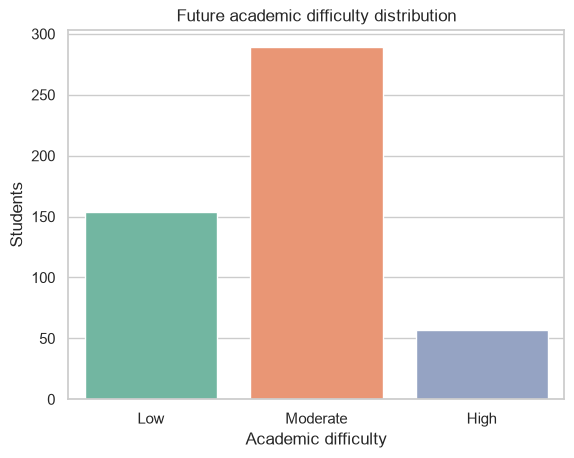

In [3]:
feature_columns = [column for column in df.columns if column not in {'student_id', 'academic_difficulty'}]
print('Missing values by column:')
display(df.isna().sum().to_frame('missing_values'))
print('Missing values total:', int(df.isna().sum().sum()))
print('Duplicate student IDs:', int(df['student_id'].duplicated().sum()))
print('Unique students:', df['student_id'].nunique())
print('Feature count:', len(feature_columns))

target_counts = df['academic_difficulty'].value_counts().sort_index()
target_table = pd.DataFrame({
    'class': target_counts.index.map(TARGET_LABELS),
    'count': target_counts.values,
    'percentage': (target_counts.values / len(df) * 100).round(2),
})
display(target_table)
sns.barplot(data=target_table, x='class', y='count', hue='class', palette='Set2', legend=False)
plt.title('Future academic difficulty distribution')
plt.xlabel('Academic difficulty')
plt.ylabel('Students')
plt.show()

## 3. Feature Correlations

,average_attendance_percentage,attendance_trend,average_quiz_score,quiz_score_trend,average_practice_hours,total_lms_resource_views,average_topic_score,topic_score_trend,academic_difficulty
average_attendance_percentage,1.00,-0.07,0.53,-0.14,0.24,0.33,0.52,-0.15,-0.31
attendance_trend,-0.07,1.00,-0.08,0.74,-0.05,-0.07,-0.08,0.75,-0.19
average_quiz_score,0.53,-0.08,1.00,-0.14,0.36,0.38,1.00,-0.15,-0.65
quiz_score_trend,-0.14,0.74,-0.14,1.00,-0.08,-0.09,-0.14,0.96,-0.22
average_practice_hours,0.24,-0.05,0.36,-0.08,1.00,0.67,0.33,-0.10,-0.13
total_lms_resource_views,0.33,-0.07,0.38,-0.09,0.67,1.00,0.33,-0.11,-0.13
average_topic_score,0.52,-0.08,1.00,-0.14,0.33,0.33,1.00,-0.16,-0.65
topic_score_trend,-0.15,0.75,-0.15,0.96,-0.10,-0.11,-0.16,1.00,-0.22
academic_difficulty,-0.31,-0.19,-0.65,-0.22,-0.13,-0.13,-0.65,-0.22,1.00


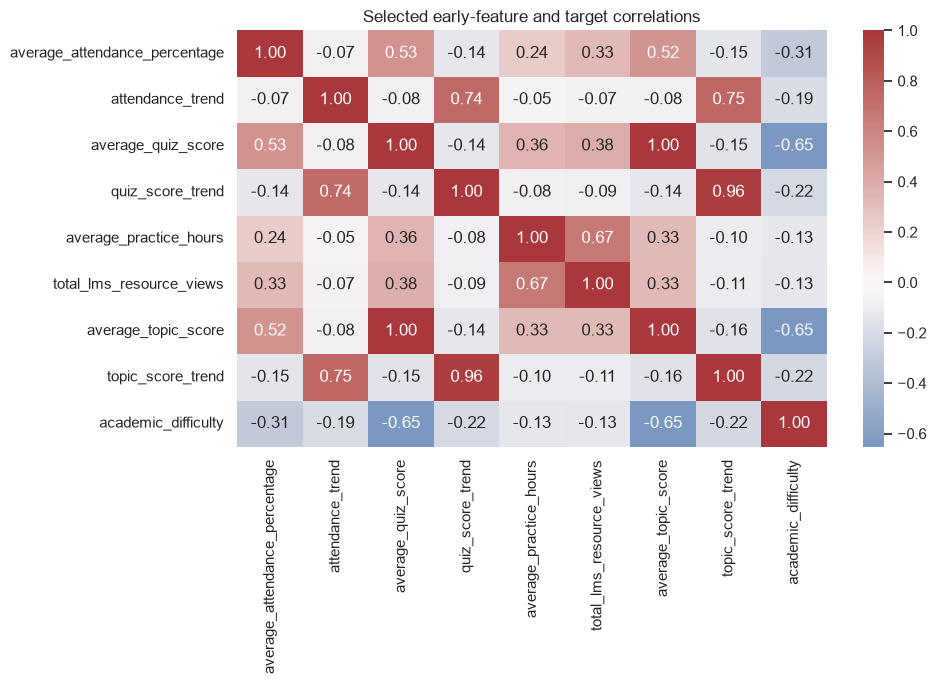

In [4]:
correlation_columns = [
    'average_attendance_percentage', 'attendance_trend',
    'average_quiz_score', 'quiz_score_trend',
    'average_practice_hours', 'total_lms_resource_views',
    'average_topic_score', 'topic_score_trend',
    'academic_difficulty',
]
correlations = df[correlation_columns].corr()
display(correlations.round(2))

plt.figure(figsize=(10, 7))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Selected early-feature and target correlations')
plt.tight_layout()
plt.show()

## 4. ML Readiness Checks

In [5]:
forbidden_columns = {
    'future_mean_topic_score', 'future_score_change',
    'week', 'subject', 'topic',
}
print('One row per student:', bool(len(df) == df['student_id'].nunique()))
print('No missing values:', bool(not df.isna().any().any()))
print('No duplicate students:', bool(not df['student_id'].duplicated().any()))
print('No future-derived feature columns:', bool(not forbidden_columns.intersection(feature_columns)))
print('Expected feature count:', len(feature_columns) == 25)
print('Input week range documented as weeks 1-6.')
print('Target week range documented as weeks 7-10.')
print('ML-ready:', 'YES for modeling experiments after selecting student-level/time-aware validation; no model has been trained.')

One row per student: True
No missing values: True
No duplicate students: True
No future-derived feature columns: True
Expected feature count: True
Input week range documented as weeks 1-6.
Target week range documented as weeks 7-10.
ML-ready: YES for modeling experiments after selecting student-level/time-aware validation; no model has been trained.


## Conclusion

The processed table is a one-row-per-student early-prediction dataset with features aggregated from weeks 1-6 only. The target is independently constructed from weeks 7-10, rather than copied from the raw `academic_difficulty` column. Structural checks should show 500 students, 25 input features, no missing values, and no duplicate students.

It is suitable for the next preprocessing/modeling stage, subject to selecting a leakage-resistant student-level validation design and documenting whether the weeks 7-10 threshold target is retained. This notebook does not train a model.